# 타이타닉 생존자 예측 — 이진 분류 모델

**목표:** 승객 정보(성별, 나이, 객실 등급, 가족 수 등)로 생존 여부(`Survived`: 0 = 사망, 1 = 생존)를 예측하는 이진 분류 모델을 만들기

**진행 순서**
1. 데이터 로드
2. 탐색적 데이터 분석(EDA) — 결측치와 생존율 패턴 확인
3. 피처 엔지니어링 — Title, FamilySize, IsAlone, HasCabin, Deck
4. 전처리 설계 — Pipeline + ColumnTransformer
5. 모델 비교 — 로지스틱 회귀(베이스라인) → 결정트리 → 랜덤 포레스트 → 그래디언트 부스팅
6. 하이퍼파라미터 튜닝 — GridSearchCV / RandomizedSearchCV
7. 성능 개선 시도 — 인코딩 변경, 보팅·스태킹, 티켓 기반 변수, 서로 다른 특성 앙상블, 반복 교차검증, Age 그룹 중앙값
8. 교차검증 기준 1차 모델 선택
9. 예측 및 1차 `submission.csv` 생성
10. 리더보드 결과 분석과 최종 제출 결정 (얕은 랜덤 포레스트)
11. 정리

## 1. 데이터 로드

결과를 재현할 수 있도록 난수 시드를 `RANDOM_STATE = 42`로 고정합니다.

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.model_selection import StratifiedKFold, cross_validate, GridSearchCV, RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.base import clone
from sklearn.ensemble import (RandomForestClassifier, GradientBoostingClassifier,
                              VotingClassifier, StackingClassifier)

RANDOM_STATE = 42
DATA_DIR = Path("data") if Path("data/train.csv").exists() else Path(".")

train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
print("train:", train.shape, "/ test:", test.shape)
train.head()

train: (891, 12) / test: (418, 11)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


- **train (891, 12):** 승객 891명의 정보와 정답 `Survived`가 있습니다.
- **test (418, 11):** `Survived` 열이 없습니다. 이 418명의 생존 여부를 예측해 제출합니다.

## 2. 탐색적 데이터 분석(EDA)

### 2-1. 결측치 비율

전처리 방법을 정하기 전에 각 컬럼이 얼마나 비어 있는지 확인

train에 없던 결측이 test에만 있을 수 있기 때문에 따로 확인

In [2]:
missing = pd.DataFrame({
    "train_missing(%)": (train.isna().mean() * 100).round(1),
    "test_missing(%)": (test.isna().mean() * 100).round(1),
})
missing[(missing > 0).any(axis=1)]

,train_missing(%),test_missing(%)
Age,19.9,20.6
Cabin,77.1,78.2
Embarked,0.2,0.0
Fare,0.0,0.2


| 컬럼 | train | test | 처리 방식과 이유 |
|---|---|---|---|
| **Age** | 19.9% | 20.6% | 약 20%가 비어 있어 열을 버리기엔 정보 손실이 크고, 채울 수 있을 만큼 값이 남아 있습니다. 이상치에 덜 흔들리는 **중앙값**으로 채우고, **결측 여부를 따로 표시하는 열**을 추가 |
| **Cabin** | 77.1% | 78.2% | 10명 중 8명이 비어 있어 값을 채우면 대부분을 지어내는 셈입니다. 채우지 않고 **"기록이 있는가(HasCabin)"와 "갑판 첫 글자(Deck)"**로 바꿔 사용 |
| **Embarked** | 0.2% (2명) | 0% | 2명뿐이라 무엇으로 채워도 결과에 거의 영향이 없으므로 가장 간단한 **최빈값**으로 채우기 |
| **Fare** | 0% | 0.2% (1명) | test에만 결측이 있습니다. 대비하지 않으면 예측 단계에서 오류가 나므로 중앙값으로 채우도록 설계 |

같은 결측치라도 **비율과 의미가 다르기 때문에** 컬럼마다 처리 방식을 다르게 정했습니다.

### 2-2. 생존율 패턴

전체 생존율과 주요 범주별 생존율을 확인 

전체 생존율은 "모두 사망으로 예측하는 모델"의 정확도를 위해 확인

In [3]:
print("전체 생존율:", round(train["Survived"].mean(), 4))
for col in ["Sex", "Pclass", "Embarked"]:
    display(train.groupby(col)["Survived"].agg(["mean", "count"]).round(3))

전체 생존율: 0.3838


,mean,count
Sex,,
female,0.742,314
male,0.189,577


,mean,count
Pclass,,
1,0.630,216
2,0.473,184
3,0.242,491


,mean,count
Embarked,,
C,0.554,168
Q,0.390,77
S,0.337,644


- **전체 생존율 0.384:** 모두 "사망"으로 예측해도 정확도가 0.616입니다. 모델은 최소한 이보다 나아야 합니다.
- **성별:** 여성 0.742, 남성 0.189로 가장 강한 패턴입니다.
- **객실 등급:** 1등석 0.63 > 2등석 0.47 > 3등석 0.24로 등급이 높을수록 많이 살았습니다.
- **승선 항구:** C 승객의 생존율이 0.55로 높습니다. 1등석 비율이 높기 때문으로 보입니다.

대회에서 제공한 `gender_submission.csv`는 "여성은 생존, 남성은 사망"으로 예측한 견본입니다. 이 규칙의 train 정확도를 모델이 넘어야 할 기준선

In [4]:
gender_rule_acc = ((train["Sex"] == "female").astype(int) == train["Survived"]).mean()
print("성별 규칙의 train 정확도:", round(gender_rule_acc, 4))

성별 규칙의 train 정확도: 0.7868


### 2-3. Age 결측 여부와 생존

나이 기록이 없는 승객의 생존율이 다르다면, "결측이다"라는 사실 자체가 정보

In [5]:
train.groupby(train["Age"].isna())["Survived"].mean().round(3)

Age
False    0.406
True     0.294
Name: Survived, dtype: float64

나이가 없는 승객(True)의 생존율 0.294가 나이가 있는 승객(False) 0.406보다 낮습니다. 그래서 Age를 중앙값으로 채우면서 **결측 여부 표시 열**(`SimpleImputer(add_indicator=True)`)도 함께 만들어 이 정보를 남깁니다.

## 3. 피처 엔지니어링

원본 컬럼만으로는 드러나지 않는 패턴을 새 변수로 만듭니다.

| 새 변수 | 만드는 방법 | 의도 |
|---|---|---|
| **Title** | `Name`에서 쉼표와 마침표 사이의 호칭 추출 | 호칭에는 성별뿐 아니라 **나이·사회적 지위** 정보가 담겨 있습니다 |
| **FamilySize** | `SibSp + Parch + 1` (+1은 본인) | 형제·배우자와 부모·자녀를 합친 가족 규모 |
| **IsAlone** | `FamilySize == 1` | 혼자 탑승했는지 여부 |
| **HasCabin** | `Cabin`이 비어 있지 않은가 | 객실 기록 유무로 등급·위치 정보를 간접적으로 담음 |
| **Deck** | `Cabin`의 첫 글자, 결측이면 `U`(Unknown) | 갑판 위치(A가 가장 위층) |

- 드물게 나오는 호칭(Dr, Rev, Col 등)은 인원이 너무 적어 과적합의 원인이 될 수 있으므로 **Rare**로 묶습니다.
- Mlle·Ms는 Miss와, Mme는 Mrs와 같은 뜻이므로 합칩니다.
- train과 test에 **같은 함수**를 적용해 두 데이터의 열이 똑같이 만들어지도록 합니다.

In [28]:
def add_features(df):
    df = df.copy()
    df["Title"] = df["Name"].str.extract(r",\s*([^\.]+)\.")[0].str.strip()
    df["Title"] = df["Title"].replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
    df["Title"] = df["Title"].where(df["Title"].isin(["Mr", "Mrs", "Miss", "Master"]), "Rare")
    df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
    df["IsAlone"] = (df["FamilySize"] == 1).astype(int)
    df["HasCabin"] = df["Cabin"].notna().astype(int)
    df["Deck"] = df["Cabin"].str[0].fillna("U")
    return df

train_fe = add_features(train)
test_fe = add_features(test)
train_fe[["Name", "Title", "SibSp", "Parch", "FamilySize", "IsAlone", "Cabin", "HasCabin", "Deck"]].head()

,Name,Title,SibSp,Parch,FamilySize,IsAlone,Cabin,HasCabin,Deck
0,"Braund, Mr. Owen Harris",Mr,1,0,2,0,NaN,0,U
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Mrs,1,0,2,0,C85,1,C
2,"Heikkinen, Miss. Laina",Miss,0,0,1,1,NaN,0,U
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Mrs,1,0,2,0,C123,1,C
4,"Allen, Mr. William Henry",Mr,0,0,1,1,NaN,0,U


### 3-1. 새 변수와 생존의 관계 확인

In [7]:
for col in ["Title", "FamilySize", "IsAlone", "HasCabin", "Deck"]:
    display(train_fe.groupby(col)["Survived"].agg(["mean", "count"]).round(3).T)

Title,Master,Miss,Mr,Mrs,Rare
mean,0.575,0.703,0.157,0.794,0.348
count,40.000,185.000,517.000,126.000,23.000


FamilySize,1,2,3,4,5,6,7,8,11
mean,0.304,0.553,0.578,0.724,0.2,0.136,0.333,0.0,0.0
count,537.000,161.000,102.000,29.000,15.0,22.000,12.000,6.0,7.0


IsAlone,0,1
mean,0.506,0.304
count,354.000,537.000


HasCabin,0,1
mean,0.3,0.667
count,687.0,204.000


Deck,A,B,C,D,E,F,G,T,U
mean,0.467,0.745,0.593,0.758,0.75,0.615,0.5,0.0,0.3
count,15.000,47.000,59.000,33.000,32.00,13.000,4.0,1.0,687.0


- **Title:** Mr 0.157 / **Master 0.575** / Miss 0.703 / Mrs 0.794. 같은 남성이라도 남자아이(Master)는 성인 남성(Mr)보다 생존율이 3배 이상 높습니다. 성별만으로는 담을 수 없던 "아이 먼저" 패턴을 Title이 담아 줍니다.
- **FamilySize:** 1명 0.30 → 2~4명 0.55~0.72 → 5명 이상 0~0.33으로 **올라갔다가 내려가는 산 모양**입니다. 혼자이거나 대가족이면 불리했습니다. 이런 비선형 관계는 직선 모델(로지스틱 회귀)이 표현하기 어렵다는 점이 5절의 성능 차이를 설명하는 근거가 됩니다.
- **IsAlone:** 혼자 0.30, 가족 동반 0.51.
- **HasCabin:** 기록 있음 0.667, 없음 0.300. 기록이 남은 승객은 대부분 1등석으로 보입니다.
- **Deck:** B·D·E 갑판이 0.75 안팎으로 높지만 갑판별 인원이 적어(T 갑판 1명) 값이 불안정합니다.

## 4. 전처리 설계: Pipeline + ColumnTransformer

**설계 의도**
1. **데이터 누수 방지:** 결측 중앙값이나 스케일링의 평균·표준편차를 전체 train으로 미리 계산하면 교차검증의 검증 fold 정보가 학습에 섞입니다. 전처리를 Pipeline 안에 넣으면 fold마다 학습 부분으로만 `fit`하므로 누수가 없습니다.
2. **train·test 일관성:** test에도 train에서 학습한 중앙값과 인코딩 규칙이 그대로 적용되고, test에만 있는 Fare 결측도 자동으로 채워집니다.
3. **범주형 인코딩:** Sex, Embarked, Title, Deck은 순서가 없는 범주이므로 **원-핫 인코딩**합니다. 숫자 0, 1, 2로 바꾸면 크기 관계가 생긴 것처럼 잘못 해석됩니다. `handle_unknown="ignore"`는 test에 처음 보는 범주가 나와도 오류가 나지 않게 합니다.
4. **스케일링은 선택:** 로지스틱 회귀는 특성 크기에 영향을 받으므로 표준화하고, "값 ≤ 기준값" 비교만 하는 트리 계열은 스케일링하지 않습니다.
5. **사용하지 않는 열:** `PassengerId`(식별 번호), `Name`(Title로 대체), `Ticket`(형식이 제각각), `Cabin`(HasCabin·Deck으로 대체)은 모델에 넣지 않습니다. ColumnTransformer에 지정하지 않은 열은 자동으로 제외됩니다.

In [29]:
NUM_COLS = ["Age", "Fare", "FamilySize", "Pclass", "IsAlone", "HasCabin"]
CAT_COLS = ["Sex", "Embarked", "Title", "Deck"]

def make_preprocess(scale=True, encoder="onehot", num_cols=None, cat_cols=None):
    num_cols = NUM_COLS if num_cols is None else num_cols
    cat_cols = CAT_COLS if cat_cols is None else cat_cols
    num_steps = [("impute", SimpleImputer(strategy="median", add_indicator=True))]
    if scale:
        num_steps.append(("scale", StandardScaler()))
    if encoder == "onehot":
        enc = OneHotEncoder(handle_unknown="ignore")
    else:
        enc = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
    return ColumnTransformer([
        ("num", Pipeline(num_steps), num_cols),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("encode", enc)]), cat_cols),
    ])

X = train_fe
y = train_fe["Survived"]
X_test = test_fe

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

## 5. 모델 비교 (기본 설정)

모델마다 5-fold 교차검증을 하고 train 정확도, 검증 정확도, 둘의 차이를 기록합니다.
- gap이 크면 학습 데이터를 외운 **과적합**
- 둘 다 낮으면 패턴을 충분히 잡지 못한 **과소적합**

| 모델 | 비교하는 이유 |
|---|---|
| 로지스틱 회귀 | 단순하고 해석하기 쉬운 선형 모델 |
| 결정트리 (제한 없음 / depth=4) | 조건 조합과 비선형 관계를 잡을 수 있음. 깊이 제한의 효과도 확인 |
| 랜덤 포레스트 | 여러 트리의 투표로 결정트리의 높은 분산을 줄임 |
| 그래디언트 부스팅 | 얕은 트리를 앞 트리의 오차를 고치는 방향으로 차례로 더함 |

In [9]:
results = []

def evaluate(name, model):
    r = cross_validate(model, X, y, cv=cv, scoring="accuracy", return_train_score=True, n_jobs=-1)
    row = {
        "model": name,
        "train_acc": r["train_score"].mean(),
        "val_acc": r["test_score"].mean(),
        "val_std": r["test_score"].std(),
    }
    row["gap"] = row["train_acc"] - row["val_acc"]
    results.append(row)
    return row

base_models = {
    "LogisticRegression": Pipeline([("pre", make_preprocess(scale=True)),
                                    ("model", LogisticRegression(max_iter=1000))]),
    "DecisionTree (no limit)": Pipeline([("pre", make_preprocess(scale=False)),
                                         ("model", DecisionTreeClassifier(random_state=RANDOM_STATE))]),
    "DecisionTree (depth=4)": Pipeline([("pre", make_preprocess(scale=False)),
                                        ("model", DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE))]),
    "RandomForest (default)": Pipeline([("pre", make_preprocess(scale=False)),
                                        ("model", RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE))]),
    "GradientBoosting (default)": Pipeline([("pre", make_preprocess(scale=False)),
                                            ("model", GradientBoostingClassifier(random_state=RANDOM_STATE))]),
}
for name, model in base_models.items():
    evaluate(name, model)

pd.DataFrame(results).round(4)

,model,train_acc,val_acc,val_std,gap
0,LogisticRegression,0.8409,0.8271,0.0181,0.0138
1,DecisionTree (no limit),0.9888,0.7867,0.0357,0.2020
2,DecisionTree (depth=4),0.8474,0.8170,0.0198,0.0303
3,RandomForest (default),0.9888,0.8125,0.0220,0.1762
4,GradientBoosting (default),0.9105,0.8440,0.0166,0.0665


### 결과 해석: 모델마다 성능이 왜 다른가

| 모델 | train | val | gap | 판단 |
|---|---|---|---|---|
| 성별 규칙(기준선) | — | 0.787 | — | |
| 로지스틱 회귀 | 0.841 | 0.827 | 0.014 | 안정적, 과적합 없음 |
| 결정트리 (제한 없음) | **0.989** | 0.787 | **0.202** | 심한 과적합, 기준선 수준 |
| 결정트리 depth=4 | 0.847 | 0.817 | 0.030 | 깊이 제한만으로 크게 개선 |
| 랜덤 포레스트 (기본) | 0.989 | 0.813 | 0.176 | 과적합 |
| 그래디언트 부스팅 (기본) | 0.911 | **0.844** | 0.067 | 기본 설정 중 최고 |

- **로지스틱 회귀:** 특성마다 가중치를 곱해 더하는 **직선 경계**입니다. 단순해서 과적합이 거의 없지만, FamilySize의 산 모양이나 "3등석이면서 여성" 같은 조합 패턴은 직접 표현하지 못합니다. Title처럼 조합 정보를 담은 변수를 만들어 준 덕분에 그래도 기준선보다 0.4% 높습니다.
- **결정트리 (제한 없음):** 끝까지 분할해 승객 한 명 한 명을 외웠습니다(train 0.99, val 0.79). 타이타닉은 같은 조건에서도 생사가 갈리는 잡음(운)이 많아, 외운 규칙이 새 데이터에 맞지 않습니다. depth=4로 제한하자 gap이 0.20 → 0.03으로 줄고 검증 점수가 0.03 올랐습니다.
- **랜덤 포레스트 (기본):** 트리 여러 개의 투표로 분산을 줄이지만, 기본 설정에서는 각 트리가 끝까지 자라 여전히 외웁니다(gap 0.18). 트리 크기를 제한하는 튜닝이 필요합니다.
- **그래디언트 부스팅:** 깊이 3의 얕은 트리를 오차를 줄이는 방향으로 차례로 더합니다. 트리 하나는 단순해 과적합이 덜하고, 여러 개가 쌓이며 복잡한 패턴을 잡기 때문에 기본 설정에서 가장 좋았습니다.

## 6. 하이퍼파라미터 튜닝

**탐색 방법 선택**
- **결정트리, 로지스틱 회귀:** 후보 조합이 적어 모든 조합을 확인하는 `GridSearchCV`를 사용합니다.
- **랜덤 포레스트, 그래디언트 부스팅:** 하이퍼파라미터가 4개라 조합이 수백 개이므로 `RandomizedSearchCV`로 30개 조합만 무작위로 확인합니다(시간 대비 효율).
- 모든 탐색은 같은 `cv`(5-fold)로 공정하게 비교합니다. `refit=True`(기본값)이므로 탐색이 끝나면 최적 설정으로 **train 전체를 다시 학습**합니다.

| 모델 | 하이퍼파라미터 | 의미 |
|---|---|---|
| 결정트리 | `max_depth`, `min_samples_leaf`, `ccp_alpha` | 트리 크기 제한과 사후 가지치기 |
| 로지스틱 회귀 | `C` | 규제의 역수(작을수록 강한 규제) |
| 랜덤 포레스트 | `n_estimators`, `max_depth`, `min_samples_leaf`, `max_features` | 트리 수, 각 트리의 크기, 분할마다 고려할 특성 수 |
| 그래디언트 부스팅 | `n_estimators`, `learning_rate`, `max_depth`, `subsample` | 트리 수, 한 단계의 반영 정도, 트리 깊이, 각 트리에 쓰는 표본 비율 |

In [10]:
searches = {}

searches["DecisionTree (tuned)"] = GridSearchCV(
    Pipeline([("pre", make_preprocess(scale=False)),
              ("model", DecisionTreeClassifier(random_state=RANDOM_STATE))]),
    {"model__max_depth": [2, 3, 4, 5, 6, 8],
     "model__min_samples_leaf": [1, 5, 10],
     "model__ccp_alpha": [0, 0.005, 0.01]},
    cv=cv, scoring="accuracy", return_train_score=True, n_jobs=-1)

searches["LogisticRegression (tuned)"] = GridSearchCV(
    Pipeline([("pre", make_preprocess(scale=True)),
              ("model", LogisticRegression(max_iter=1000))]),
    {"model__C": [0.01, 0.1, 1, 10, 100]},
    cv=cv, scoring="accuracy", return_train_score=True, n_jobs=-1)

searches["RandomForest (tuned)"] = RandomizedSearchCV(
    Pipeline([("pre", make_preprocess(scale=False)),
              ("model", RandomForestClassifier(random_state=RANDOM_STATE))]),
    {"model__n_estimators": [200, 300, 500],
     "model__max_depth": [4, 5, 6, 7, 8, None],
     "model__min_samples_leaf": [1, 2, 4, 8],
     "model__max_features": ["sqrt", 0.5, None]},
    n_iter=30, cv=cv, scoring="accuracy", random_state=RANDOM_STATE, return_train_score=True, n_jobs=-1)

searches["GradientBoosting (tuned)"] = RandomizedSearchCV(
    Pipeline([("pre", make_preprocess(scale=False)),
              ("model", GradientBoostingClassifier(random_state=RANDOM_STATE))]),
    {"model__n_estimators": [100, 200, 300],
     "model__learning_rate": [0.01, 0.05, 0.1],
     "model__max_depth": [2, 3, 4],
     "model__subsample": [0.7, 0.85, 1.0]},
    n_iter=30, cv=cv, scoring="accuracy", random_state=RANDOM_STATE, return_train_score=True, n_jobs=-1)

tuned_rows = []
for name, search in searches.items():
    search.fit(X, y)
    i = search.best_index_
    tuned_rows.append({
        "model": name,
        "best_params": search.best_params_,
        "train_acc": search.cv_results_["mean_train_score"][i],
        "val_acc": search.best_score_,
        "val_std": search.cv_results_["std_test_score"][i],
        "gap": search.cv_results_["mean_train_score"][i] - search.best_score_,
    })

pd.DataFrame(tuned_rows).round(4)

,model,best_params,train_acc,val_acc,val_std,gap
0,DecisionTree (tuned),"{'model__ccp_alpha': 0.005, 'model__max_depth'...",0.8401,0.8215,0.0184,0.0185
1,LogisticRegression (tuned),{'model__C': 10},0.8401,0.8283,0.0163,0.0118
2,RandomForest (tuned),"{'model__n_estimators': 300, 'model__min_sampl...",0.9127,0.8417,0.0181,0.0710
3,GradientBoosting (tuned),"{'model__subsample': 0.85, 'model__n_estimator...",0.9475,0.8496,0.0195,0.0980


### 튜닝 결과 해석

| 모델 | 찾은 설정 | train | val | 기본 → 튜닝 |
|---|---|---|---|---|
| 결정트리 | depth 5, ccp_alpha 0.005 | 0.840 | 0.822 | 0.787 → 0.822 |
| 로지스틱 회귀 | C = 10 | 0.840 | 0.828 | 0.827 → 0.828 |
| 랜덤 포레스트 | depth 8, leaf 2, 300그루, max_features=None | 0.913 | 0.842 | 0.813 → 0.842 |
| **그래디언트 부스팅** | depth 4, lr 0.1, 100그루, subsample 0.85 | 0.948 | **0.850** | 0.844 → 0.850 |

- **과적합 관찰:** 결정트리(gap 0.20 → 0.02)와 랜덤 포레스트(gap 0.18 → 0.07)는 크기를 제한하자 gap이 크게 줄면서 검증 점수가 올랐습니다. 모델의 분산을 줄이면 일반화 성능이 좋아진다는 원리가 그대로 나타났습니다.
- **로지스틱 회귀:** 원래 과적합이 없던 모델이라 규제 강도를 바꿔도 거의 차이가 없었습니다.
- **그래디언트 부스팅:** 검증 점수가 가장 높지만 gap도 0.10으로 남아 있습니다. 검증 점수 자체가 가장 높으므로 일반화 성능이 가장 좋다고 판단하되, 학습 데이터에 어느 정도 맞춰져 있다는 점은 기억해 둡니다.

## 7. 성능 개선 시도

### 7-1. 인코딩 방식 변경

원-핫 대신 범주를 정수 하나로 바꾸는 순서 인코딩(OrdinalEncoder)을 쓰면 성능이 어떻게 달라지는지 확인

In [11]:
evaluate("RandomForest (default, ordinal)",
         Pipeline([("pre", make_preprocess(scale=False, encoder="ordinal")),
                   ("model", RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE))]))
pd.DataFrame(results).round(4).query("model.str.startswith('RandomForest')")

,model,train_acc,val_acc,val_std,gap
3,RandomForest (default),0.9888,0.8125,0.0220,0.1762
5,"RandomForest (default, ordinal)",0.9888,0.8058,0.0211,0.1830


순서 인코딩은 0.813 → 0.806으로 **오히려 낮아졌습니다.** 최종 모델은 원-핫 인코딩을 유지합니다.

### 7-2. 여러 모델 결합: 보팅과 스태킹

- **소프트 보팅:** 세 모델(로지스틱 회귀, RF, GB)이 예측한 생존 확률을 평균 냅니다.
- **스태킹:** 세 모델의 예측을 입력으로 받아, 로지스틱 회귀가 "어떤 모델을 얼마나 믿을지"를 다시 학습합니다.

서로 다른 방식으로 실수하는 모델을 합치면 오차가 상쇄될 것이라는 기대에서 시도합니다.

In [12]:
ensemble_members = [
    ("lr", searches["LogisticRegression (tuned)"].best_estimator_),
    ("rf", searches["RandomForest (tuned)"].best_estimator_),
    ("gb", searches["GradientBoosting (tuned)"].best_estimator_),
]
evaluate("Voting (soft)", VotingClassifier(ensemble_members, voting="soft"))
evaluate("Stacking", StackingClassifier(ensemble_members,
                                        final_estimator=LogisticRegression(), cv=5))
pd.DataFrame(results).round(4).tail(2)

,model,train_acc,val_acc,val_std,gap
6,Voting (soft),0.9097,0.8473,0.0188,0.0623
7,Stacking,0.9111,0.8485,0.0179,0.0626


- 소프트 보팅 0.847, 스태킹 0.849로 그래디언트 부스팅 단독(0.850)과 **거의 같습니다.**
- 세 모델이 모두 같은 특성(Title, Sex, Pclass)에 크게 의존해 **틀리는 승객도 대부분 겹치기** 때문에, 합쳐도 오차가 상쇄되지 않았습니다. 앙상블은 서로 다른 실수를 하는 모델을 합칠 때 효과가 큽니다.

### 7-3. 티켓 기반 변수: TicketGroupSize, FarePerPerson

**아이디어**
- 같은 티켓 번호를 가진 승객은 **함께 여행한 일행**입니다. 가족(SibSp, Parch)에는 잡히지 않는 친구·하인·동행자까지 포함합니다.
- `Fare`는 1인 요금이 아니라 **티켓 단위의 합계 금액**입니다. 그래서 일행이 많으면 3등석이어도 요금이 커집니다(3등석 최대 69.55). 같은 티켓 인원 수로 나눈 **1인당 요금**이 실제 객실 등급을 더 정확히 반영할 것으로 예상합니다.

**계산 방식과 누수 검토**
- 같은 일행이 train과 test에 나뉘어 있는 경우가 있습니다(공유되는 티켓 번호 115개). 그래서 인원 수는 **train과 test의 Ticket을 합쳐서** 셉니다.
- 이 계산은 정답(`Survived`)을 전혀 쓰지 않고 탑승 명단만 사용합니다. 승선 명단은 예측 시점에도 알 수 있는 정보이므로 정답 누수가 아닙니다.

In [30]:
ticket_counts = pd.concat([train["Ticket"], test["Ticket"]]).value_counts()
print("train·test에 함께 있는 티켓 번호 수:", len(set(train["Ticket"]) & set(test["Ticket"])))

for df in (train_fe, test_fe):
    df["TicketGroupSize"] = df["Ticket"].map(ticket_counts)
    df["FarePerPerson"] = df["Fare"] / df["TicketGroupSize"] 

display(train_fe.groupby("TicketGroupSize")["Survived"].agg(["mean", "count"]).round(3).T)
display(train_fe.groupby("Pclass")[["Fare", "FarePerPerson"]].max().round(2))
display(train_fe[["Fare", "FarePerPerson", "Pclass"]].corr().round(3))

train·test에 함께 있는 티켓 번호 수: 115


TicketGroupSize,1,2,3,4,5,6,7,8,11
mean,0.27,0.514,0.653,0.727,0.333,0.211,0.208,0.385,0.0
count,481.00,181.000,101.000,44.000,21.000,19.000,24.000,13.000,7.0


,Fare,FarePerPerson
Pclass,,
1,512.33,128.08
2,73.50,16.00
3,69.55,19.97


,Fare,FarePerPerson,Pclass
Fare,1.000,0.827,-0.549
FarePerPerson,0.827,1.000,-0.763
Pclass,-0.549,-0.763,1.000


- **TicketGroupSize:** 1명 0.27 → 2~4명 0.51~0.73 → 5명 이상 0~0.39. FamilySize처럼 **산 모양**이지만, 가족이 아닌 동행자까지 포함해 1인 탑승객(481명)을 더 정확히 가려냅니다(IsAlone 기준 537명).
- **FarePerPerson:** 3등석 최대 요금이 69.55 → 19.97로 줄어 이상치가 사라졌습니다. Pclass와의 상관도 −0.549 → **−0.763**으로 강해졌습니다. 1인당 요금이 객실 등급을 더 정확히 반영한다는 예상이 맞았습니다.

이제 두 변수를 추가한 열 목록으로 모델을 다시 비교합니다. 앞에서 튜닝한 설정은 기존 특성 기준이므로, RF와 GB는 **새 특성으로 다시 튜닝**합니다.

In [31]:
NUM_COLS_V2 = NUM_COLS + ["TicketGroupSize", "FarePerPerson"]
X = train_fe
X_test = test_fe

evaluate("LogisticRegression +ticket",
         Pipeline([("pre", make_preprocess(scale=True, num_cols=NUM_COLS_V2)),
                   ("model", LogisticRegression(C=10, max_iter=1000))]))

for name, base in [("RandomForest", searches["RandomForest (tuned)"]),
                   ("GradientBoosting", searches["GradientBoosting (tuned)"])]:
    search = RandomizedSearchCV(
        Pipeline([("pre", make_preprocess(scale=False, num_cols=NUM_COLS_V2)),
                  ("model", base.best_estimator_.named_steps["model"].__class__(random_state=RANDOM_STATE))]),
        base.param_distributions,
        n_iter=30, cv=cv, scoring="accuracy", random_state=RANDOM_STATE, return_train_score=True, n_jobs=-1)
    search.fit(X, y)
    searches[f"{name} +ticket (tuned)"] = search
    i = search.best_index_
    tuned_rows.append({
        "model": f"{name} +ticket (tuned)",
        "best_params": search.best_params_,
        "train_acc": search.cv_results_["mean_train_score"][i],
        "val_acc": search.best_score_,
        "val_std": search.cv_results_["std_test_score"][i],
        "gap": search.cv_results_["mean_train_score"][i] - search.best_score_,
    })

pd.DataFrame(tuned_rows).round(4).tail(2)

,model,best_params,train_acc,val_acc,val_std,gap
6,RandomForest +ticket (tuned),"{'model__n_estimators': 300, 'model__min_sampl...",0.9183,0.8552,0.0104,0.0631
7,GradientBoosting +ticket (tuned),"{'model__subsample': 0.85, 'model__n_estimator...",0.8911,0.8518,0.0147,0.0393


| 모델 | 기존 특성 | **+ 티켓 변수** | 변화 |
|---|---|---|---|
| 로지스틱 회귀 (C=10) | 0.828 | 0.825 | −0.003 |
| 그래디언트 부스팅 (재튜닝) | 0.850 | 0.852 | +0.002, gap 0.098 → 0.039 |
| **랜덤 포레스트 (재튜닝)** | 0.842 | **0.855** | **+0.013**, gap 0.071 → 0.063, std 0.018 → **0.010** |

- **랜덤 포레스트가 가장 크게 좋아졌습니다.** 검증 점수가 오르고, gap과 fold 간 편차까지 함께 줄었습니다.
- **로지스틱 회귀는 오히려 조금 낮아졌습니다.** TicketGroupSize의 산 모양은 직선으로 표현할 수 없습니다. 또 기존 변수와 겹치는 정보가 늘어 가중치가 불안정해졌기 때문으로 보입니다.

### 7-4. 서로 다른 특성을 쓰는 모델끼리의 앙상블

7-2에서 앙상블 효과가 없었던 이유는, 세 모델이 같은 특성을 써서 **같은 승객을 틀렸기** 때문입니다. 이번에는 모델마다 **보는 특성을 일부러 다르게** 해서, 서로 다른 실수를 하도록 만듭니다.

| 모델 | 사용 특성 | 관점 |
|---|---|---|
| **A: 로지스틱 회귀** | Age, Pclass, FamilySize, Sex, Title | "**누구인가**" (인적 정보) |
| **B: 랜덤 포레스트** | Fare, FarePerPerson, TicketGroupSize, Pclass, HasCabin, Deck, Embarked | "**어떤 표·객실인가**" (티켓·객실 정보, 성별 없음) |
| **C: 그래디언트 부스팅** | 전체 특성 + 티켓 변수 | 전체 |

먼저 세 모델이 **얼마나 다른 승객을 틀리는지** 확인합니다. `cross_val_predict`는 각 승객이 검증 fold에 있을 때의 예측을 모아 줍니다.

In [15]:
from sklearn.model_selection import cross_val_predict

model_A = Pipeline([("pre", make_preprocess(scale=True, num_cols=["Age", "Pclass", "FamilySize"],
                                            cat_cols=["Sex", "Title"])),
                    ("model", LogisticRegression(C=10, max_iter=1000))])
model_B = Pipeline([("pre", make_preprocess(scale=False,
                                            num_cols=["Fare", "FarePerPerson", "TicketGroupSize", "Pclass", "HasCabin"],
                                            cat_cols=["Deck", "Embarked"])),
                    ("model", RandomForestClassifier(n_estimators=300, max_depth=6, min_samples_leaf=2,
                                                     random_state=RANDOM_STATE))])
model_C = searches["GradientBoosting +ticket (tuned)"].best_estimator_

oof = {name: cross_val_predict(m, X, y, cv=cv, n_jobs=-1)
       for name, m in [("A", model_A), ("B", model_B), ("C", model_C)]}
wrong = {name: (pred != y) for name, pred in oof.items()}

print("각 모델의 정확도:", {k: round((v == y).mean(), 4) for k, v in oof.items()})
print("틀린 승객 수    :", {k: int(v.sum()) for k, v in wrong.items()})
print("둘 다 틀린 승객 : A∩B", int((wrong["A"] & wrong["B"]).sum()),
      "/ A∩C", int((wrong["A"] & wrong["C"]).sum()),
      "/ B∩C", int((wrong["B"] & wrong["C"]).sum()))
print("예측 일치율     : A-B", round((oof["A"] == oof["B"]).mean(), 3),
      "/ A-C", round((oof["A"] == oof["C"]).mean(), 3),
      "/ B-C", round((oof["B"] == oof["C"]).mean(), 3))

각 모델의 정확도: {'A': np.float64(0.8249), 'B': np.float64(0.7273), 'C': np.float64(0.8519)}
틀린 승객 수    : {'A': 156, 'B': 243, 'C': 132}
둘 다 틀린 승객 : A∩B 69 / A∩C 110 / B∩C 77
예측 일치율     : A-B 0.707 / A-C 0.924 / B-C 0.752


- 특성을 나누자 예측이 실제로 **다양해졌습니다.**
  - A-B 예측 일치율이 0.707입니다. 7-2처럼 같은 특성을 쓴 RF와 GB는 0.96이었습니다.
  - A가 틀린 156명 중 B도 틀린 승객은 69명뿐입니다.
- 하지만 **B 단독 정확도가 0.727로 너무 낮습니다.** 성별 정보 없이 티켓·객실만으로는 잘 맞히지 못하기 때문입니다.
- 앙상블이 효과를 보려면 두 조건이 **함께** 필요합니다.
  - 모델들이 서로 다른 실수를 해야 합니다(다양성).
  - 각 모델이 어느 정도는 잘 맞혀야 합니다(정확도).

두 가지 조합을 비교합니다.
1. **다양성 우선:** A + B + C
2. **정확도와 다양성의 절충:** A(인적 정보 LR) + RF(+티켓) + GB(+티켓). 서로 다른 알고리즘이고, A는 특성 집합도 다릅니다.

In [16]:
model_RF2 = searches["RandomForest +ticket (tuned)"].best_estimator_

ensembles = {
    "Voting soft (A+B+C, diverse features)": VotingClassifier(
        [("A", model_A), ("B", model_B), ("C", model_C)], voting="soft"),
    "Stacking (A+B+C, diverse features)": StackingClassifier(
        [("A", model_A), ("B", model_B), ("C", model_C)], final_estimator=LogisticRegression(), cv=5),
    "Voting soft (A+RF2+GB2)": VotingClassifier(
        [("A", model_A), ("rf", model_RF2), ("gb", model_C)], voting="soft"),
}
for name, m in ensembles.items():
    evaluate(name, m)
pd.DataFrame(results).round(4).tail(3)

,model,train_acc,val_acc,val_std,gap
9,"Voting soft (A+B+C, diverse features)",0.8911,0.8485,0.0161,0.0427
10,"Stacking (A+B+C, diverse features)",0.8791,0.8451,0.0113,0.0340
11,Voting soft (A+RF2+GB2),0.8889,0.8485,0.0149,0.0404


| 앙상블 | val |
|---|---|
| 보팅 A+B+C (특성 분리) | 0.849 |
| 스태킹 A+B+C (특성 분리) | 0.845 |
| 보팅 A+RF2+GB2 | 0.849 |
| *(비교) RF + 티켓 단독* | ***0.855*** |

- 세 앙상블 모두 **RF + 티켓 단독(0.855)을 넘지 못했습니다.**
- 약한 모델 B를 넣으면 다양성은 커지지만 평균 정확도가 낮아져 손해가 이득을 상쇄했습니다.
- 강한 모델끼리 합치면 다시 서로 비슷해집니다.
- 이 데이터에서는 **좋은 특성을 하나 더 만든 것(7-3)이 모델을 합치는 것보다 효과가 컸습니다.**

### 7-5. 반복 교차검증으로 상위 후보 재확인

지금까지의 점수는 모두 **한 가지 5-fold 분할**(`random_state=42`)로 계산했습니다. 이 점수에는 두 가지 불확실성이 있습니다.
1. 분할 방식이 달라지면 점수가 달라집니다(fold 간 표준편차 약 0.02).
2. **튜닝에 쓴 분할로 다시 평가하면** 그 분할에 잘 맞는 설정을 고른 셈이라 점수가 낙관적으로 나옵니다.

그래서 **다른 시드로 5-fold를 3번 반복**(총 15번 평가)해서, 상위 후보의 순위가 유지되는지 확인합니다.

In [17]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score

repeated_cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=7)   # 튜닝에 쓰지 않은 분할
finalists = {
    "GradientBoosting (tuned)": searches["GradientBoosting (tuned)"].best_estimator_,
    "RandomForest (tuned)": searches["RandomForest (tuned)"].best_estimator_,
    "GradientBoosting +ticket (tuned)": model_C,
    "RandomForest +ticket (tuned)": model_RF2,
    "Voting soft (A+RF2+GB2)": ensembles["Voting soft (A+RF2+GB2)"],
}
repeated_rows = []
for name, m in finalists.items():
    scores = cross_val_score(m, X, y, cv=repeated_cv, scoring="accuracy", n_jobs=-1)
    repeated_rows.append({"model": name, "repeated_mean": scores.mean(), "repeated_std": scores.std()})
pd.DataFrame(repeated_rows).sort_values("repeated_mean", ascending=False).round(4)

,model,repeated_mean,repeated_std
3,RandomForest +ticket (tuned),0.8470,0.0200
4,Voting soft (A+RF2+GB2),0.8440,0.0196
2,GradientBoosting +ticket (tuned),0.8417,0.0220
1,RandomForest (tuned),0.8350,0.0259
0,GradientBoosting (tuned),0.8339,0.0240


| 모델 | 처음 5-fold | **반복 5-fold × 3** |
|---|---|---|
| **RandomForest + 티켓** | 0.855 | **0.847** ± 0.020 |
| Voting (A+RF2+GB2) | 0.849 | 0.844 ± 0.020 |
| GradientBoosting + 티켓 | 0.852 | 0.842 ± 0.022 |
| RandomForest (기존 특성) | 0.842 | 0.835 ± 0.026 |
| GradientBoosting (기존 특성) | 0.850 | **0.834** ± 0.024 |

- **모든 모델의 점수가 내려갔습니다.** 튜닝에 쓴 분할로 평가한 점수가 낙관적이었다는 뜻입니다.
- 특히 처음에 최고였던 **GB(기존 특성)는 0.850 → 0.834로 가장 많이 떨어졌습니다.** 이 분할에 운 좋게 잘 맞는 설정이 뽑혔던 것으로 보입니다.
- **RF + 티켓은 두 평가 모두에서 1위**이고 표준편차도 작아, 순위가 분할에 따라 바뀌지 않았습니다.
- 티켓 변수의 효과도 반복 평가에서 유지됩니다(RF +0.012, GB +0.008). 한 번의 분할에서 우연히 나온 차이가 아닌것으로 보입니다

### 7-6. Age를 Title·Pclass별 중앙값으로 채우기

**아이디어:** 지금은 Age 결측을 전체 중앙값(28세) 하나로 채웁니다. 그런데 나이는 호칭과 객실 등급에 따라 크게 다릅니다(아래 표). 남자아이(Master)의 빈 나이를 28세로 채우면 사실과 거리가 멉니다. 같은 Title·Pclass 그룹의 중앙값으로 채우면 더 그럴듯한 값이 될 것으로 예상합니다.

In [18]:
display(train_fe.pivot_table(index="Title", columns="Pclass", values="Age", aggfunc="median"))
display(train_fe[train_fe["Age"].isna()].groupby(["Title", "Pclass"]).size().rename("Age 결측 수").to_frame().T)

Pclass,1,2,3
Title,,,
Master,4.0,1.0,4.0
Miss,30.0,24.0,18.0
Mr,40.0,31.0,26.0
Mrs,40.0,32.0,31.0
Rare,48.5,46.5,NaN


Title    Master Miss         Mr        Mrs    Rare
Pclass        3    1  2   3   1  2   3   1  3    1
Age 결측 수      4    1  2  33  20  9  90   8  9    1

- 같은 Mr라도 1등석은 40세, 3등석은 26세입니다. Master는 등급과 관계없이 1~4세입니다.
- 결측은 3등석 Mr(90명)과 3등석 Miss(33명)에 몰려 있습니다. 이들을 28세 대신 각각 26세와 18세로 채우게 됩니다.
- Rare × 3등석처럼 **나이가 하나도 없는 그룹**이 있습니다. 이때는 Title 중앙값, 그것도 없으면 전체 중앙값으로 채웁니다.

**누수 방지 설계:** 그룹 중앙값을 전체 train으로 미리 계산하면, 교차검증에서 검증 fold의 나이가 중앙값 계산에 섞입니다. 그래서 `fit`에서 중앙값을 학습하고 `transform`에서 채우는 클래스를 만들어 Pipeline 맨 앞에 넣습니다.
- 이렇게 하면 `SimpleImputer`처럼 fold마다 학습 부분으로만 중앙값을 계산합니다.
- 채우기 전에 결측 여부를 `AgeMissing` 열로 남겨, 2-3에서 확인한 "기록 없음" 정보도 유지합니다.

In [32]:
from sklearn.base import BaseEstimator, TransformerMixin

class GroupAgeImputer(BaseEstimator, TransformerMixin):
    """fit: 그룹별 Age 중앙값 학습 / transform: 결측 표시 열을 만든 뒤 Age를 그룹 중앙값으로 채움"""

    def __init__(self, keys=("Title", "Pclass")):
        self.keys = keys

    def fit(self, X, y=None):
        keys = list(self.keys)
        self.group_median_ = X.groupby(keys)["Age"].median()     # 1순위: 그룹 중앙값
        self.first_key_median_ = X.groupby(keys[0])["Age"].median()   # 2순위: 첫 번째 키(Title) 중앙값
        self.overall_median_ = X["Age"].median()                 # 3순위: 전체 중앙값
        return self

    def transform(self, X):
        X = X.copy()
        missing = X["Age"].isna()
        group_index = pd.MultiIndex.from_frame(X[list(self.keys)])
        fill = pd.Series(self.group_median_.reindex(group_index).to_numpy(), index=X.index)
        fill = fill.fillna(X[self.keys[0]].map(self.first_key_median_)).fillna(self.overall_median_)
        X["AgeMissing"] = missing.astype(int)
        X["Age"] = X["Age"].fillna(fill)
        return X

age_check = GroupAgeImputer().fit(X).transform(X_test)
print("test Age 결측:", X_test["Age"].isna().sum(), "→", age_check["Age"].isna().sum())

test Age 결측: 86 → 0


세 가지 채우기 방식을 세 모델에서 비교합니다. 하이퍼파라미터는 7-3에서 튜닝한 값을 그대로 쓰고, **채우기 방식만** 바꿉니다.
- 전체 중앙값(현재)
- Title별 중앙값
- Title·Pclass별 중앙값

7-5의 교훈에 따라 처음 5-fold와 반복 5-fold × 3을 함께 봅니다.

In [20]:
NUM_COLS_AGE = NUM_COLS_V2 + ["AgeMissing"]
age_models = {
    "LogisticRegression": (lambda: LogisticRegression(C=10, max_iter=1000), True),
    "RandomForest": (lambda: clone(model_RF2.named_steps["model"]), False),
    "GradientBoosting": (lambda: clone(model_C.named_steps["model"]), False),
}
age_methods = {
    "전체 중앙값": None,
    "Title 중앙값": ("Title",),
    "Title·Pclass 중앙값": ("Title", "Pclass"),
}

age_rows = []
for model_name, (make_model, scale) in age_models.items():
    for method_name, keys in age_methods.items():
        if keys is None:
            pipe = Pipeline([("pre", make_preprocess(scale=scale, num_cols=NUM_COLS_V2)),
                             ("model", make_model())])
        else:
            pipe = Pipeline([("age", GroupAgeImputer(keys=keys)),
                             ("pre", make_preprocess(scale=scale, num_cols=NUM_COLS_AGE)),
                             ("model", make_model())])
        once = cross_val_score(pipe, X, y, cv=cv, scoring="accuracy", n_jobs=-1)
        repeated = cross_val_score(pipe, X, y, cv=repeated_cv, scoring="accuracy", n_jobs=-1)
        age_rows.append({"model": model_name, "age_fill": method_name,
                         "val_5fold": once.mean(), "val_repeated": repeated.mean(),
                         "repeated_std": repeated.std()})

pd.DataFrame(age_rows).round(4)

,model,age_fill,val_5fold,val_repeated,repeated_std
0,LogisticRegression,전체 중앙값,0.8249,0.8234,0.0280
1,LogisticRegression,Title 중앙값,0.8283,0.8283,0.0285
2,LogisticRegression,Title·Pclass 중앙값,0.8316,0.8302,0.0250
3,RandomForest,전체 중앙값,0.8552,0.8470,0.0200
4,RandomForest,Title 중앙값,0.8496,0.8444,0.0222
5,RandomForest,Title·Pclass 중앙값,0.8451,0.8399,0.0199
6,GradientBoosting,전체 중앙값,0.8518,0.8417,0.0220
7,GradientBoosting,Title 중앙값,0.8496,0.8417,0.0210
8,GradientBoosting,Title·Pclass 중앙값,0.8518,0.8403,0.0232


| 모델 | 전체 중앙값 | Title 중앙값 | Title·Pclass 중앙값 |
|---|---|---|---|
| 로지스틱 회귀 (반복) | 0.823 | 0.828 | **0.830** (+0.007) |
| 랜덤 포레스트 (반복) | **0.847** | 0.844 | 0.840 (−0.007) |
| 그래디언트 부스팅 (반복) | **0.842** | **0.842** | 0.840 |

**결과가 모델에 따라 반대로 나왔습니다.**
- **로지스틱 회귀는 좋아졌습니다.** 직선 모델은 "Age × Title"처럼 특성을 조합하지 못합니다. 그래서 결측 승객에게 그룹에 맞는 나이를 미리 넣어 주는 것이 그대로 도움이 됩니다.
- **트리 계열(RF, GB)은 좋아지지 않거나 조금 낮아졌습니다.**
  - 트리는 Title과 Pclass를 이미 분할 조건으로 쓰고 있어서, 그룹별 나이 정보를 스스로 조합할 수 있습니다.
  - 그룹 중앙값으로 채우면 결측 승객의 나이가 실제 나이처럼 섞입니다. 예를 들어 3등석 Mr 90명 모두 26세가 됩니다. 그러면 "실제로 26세 근처인 승객"과 구분하기가 오히려 어려워지는 것으로 보입니다.
  - 전체 중앙값(28세)으로 채우면 결측 승객이 28이라는 한 값에 모입니다. 트리 입장에서는 결측 여부 열과 함께 "기록 없음" 집단을 더 분명하게 구분할 수 있습니다.
- **결론:** **어떤 모델이 그 값을 쓰는지**에 따라 효과가 다릅니다.
  - 최종 모델인 랜덤 포레스트에서는 전체 중앙값이 가장 좋으므로 **기존 방식을 유지**합니다.
  - 로지스틱 회귀를 쓴다면 Title·Pclass 중앙값이 낫습니다.

## 8. 전체 비교와 최종 모델 선택

In [21]:
summary = pd.concat([pd.DataFrame(results), pd.DataFrame(tuned_rows).drop(columns="best_params")])
summary = summary.drop_duplicates("model").sort_values("val_acc", ascending=False).reset_index(drop=True)
summary.round(4)

,model,train_acc,val_acc,val_std,gap
0,RandomForest +ticket (tuned),0.9183,0.8552,0.0104,0.0631
1,GradientBoosting +ticket (tuned),0.8911,0.8518,0.0147,0.0393
2,GradientBoosting (tuned),0.9475,0.8496,0.0195,0.0980
3,Stacking,0.9111,0.8485,0.0179,0.0626
4,Voting soft (A+RF2+GB2),0.8889,0.8485,0.0149,0.0404
5,"Voting soft (A+B+C, diverse features)",0.8911,0.8485,0.0161,0.0427
6,Voting (soft),0.9097,0.8473,0.0188,0.0623
7,"Stacking (A+B+C, diverse features)",0.8791,0.8451,0.0113,0.0340
8,GradientBoosting (default),0.9105,0.8440,0.0166,0.0665
9,RandomForest (tuned),0.9127,0.8417,0.0181,0.0710


### 1차 선택 (교차검증 기준): 랜덤 포레스트 + 티켓 변수 (튜닝)


설정은 `max_depth=8`, `min_samples_leaf=2`, `max_features=None`, 300그루입니다.

**선택 이유**
1. **검증 정확도가 가장 높습니다.**
   - 처음 5-fold 0.855, 반복 5-fold × 3 0.847로 **두 평가 모두 1위**입니다.
   - 성별 규칙 기준선(0.787)보다 약 6~7%p, 로지스틱 회귀 베이스라인(0.827)보다 약 2~3%p 높습니다.
2. **안정적입니다.**
   - 처음 평가의 fold 간 표준편차가 0.010으로 후보 중 가장 작습니다.
   - 처음에 1위였던 GB(기존 특성)는 반복 평가에서 0.834로 떨어졌지만, RF + 티켓은 순위가 유지되었습니다.
3. **2위 후보보다 낫고, 앙상블보다 단순합니다.**
   - GB + 티켓은 gap이 0.039로 더 작습니다. 하지만 반복 평가 점수(0.842)가 낮고 편차(0.022)가 커서 RF를 택했습니다.
   - RF의 gap 0.063은 제한 없는 트리(0.20)와 비교하면 충분히 작은 편입니다.
   - 앙상블(보팅·스태킹)보다 점수가 높으면서 모델이 하나라 설명하기 쉽습니다.

### 최종 모델의 특성 중요도

모델이 어떤 특성을 많이 사용했는지 확인합니다. 이 값은 **이 모델의 분할에 대한 기여도**이며 생존의 원인을 뜻하지는 않습니다.

In [22]:
final_model = searches["RandomForest +ticket (tuned)"].best_estimator_
feature_names = final_model.named_steps["pre"].get_feature_names_out()
importances = final_model.named_steps["model"].feature_importances_
pd.Series(importances, index=feature_names).sort_values(ascending=False).head(10).round(3)

cat__Title_Mr           0.272
num__FarePerPerson      0.121
num__Age                0.106
num__Fare               0.092
num__Pclass             0.077
cat__Sex_female         0.074
cat__Sex_male           0.068
num__FamilySize         0.049
num__TicketGroupSize    0.042
cat__Title_Rare         0.024
dtype: float64

- 1위는 Title_Mr(0.272)입니다.
- **새로 만든 FarePerPerson(0.121)이 2위**로, 기존 Fare(0.092)보다 높습니다. 모델이 합계 요금보다 1인당 요금을 더 유용하게 썼다는 뜻입니다.
- TicketGroupSize(0.042)도 상위 10위 안에 들어 실제로 활용되었습니다.
- Fare와 FarePerPerson, Title_Mr과 Sex처럼 비슷한 정보를 나눠 가진 변수는 중요도도 나눠 갖습니다. 그래서 한쪽이 낮게 나와도 그 특성이 쓸모없다는 뜻은 아닙니다.

## 9. 예측 및 1차 제출 파일 생성

- `final_model`은 탐색 후 `refit`으로 **train 891명 전체를 학습한 상태**이므로 바로 test를 예측합니다. test에도 7-3에서 같은 방식으로 티켓 변수를 추가했습니다.
- 제출 파일은 `gender_submission.csv`와 같은 형식이어야 합니다.
  - 열: `PassengerId`, `Survived` 두 개
  - 행: 418개
  - `index=False`를 빠뜨리면 번호 열이 추가되어 형식 오류가 납니다.

In [34]:
test_pred = final_model.predict(X_test)

submission = pd.DataFrame({
    "PassengerId": test["PassengerId"],
    "Survived": test_pred.astype(int),
})
submission.to_csv("submission.csv", index=False)

print(submission.shape)
print("예측 생존 비율:", round(submission["Survived"].mean(), 3), "/ train 실제 생존율:", round(y.mean(), 3))
submission.head()

(418, 2)
예측 생존 비율: 0.385 / train 실제 생존율: 0.384


,PassengerId,Survived
0,892,0
1,893,1
2,894,0
3,895,0
4,896,1


- 예측 생존 비율이 train의 실제 생존율(0.38)과 비슷해, 한쪽으로 치우친 예측이 아님을 간단히 확인했습니다.

## 10. 리더보드 결과와 최종 제출 재검토

### 10-1. 1차 제출 결과

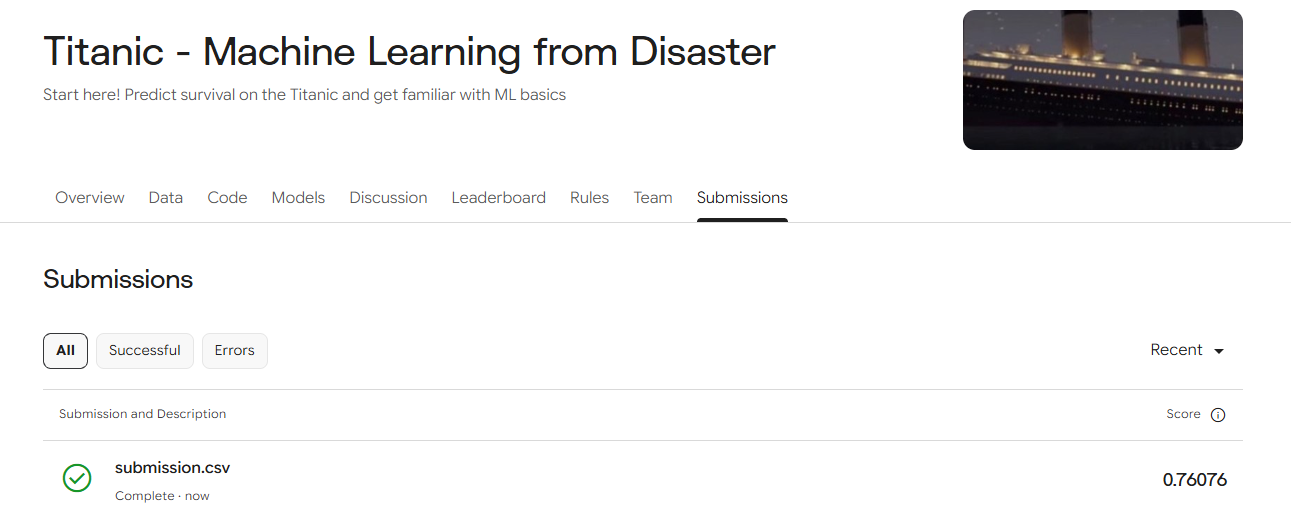

1차로 제출한 RF + 티켓 모델의 리더보드 점수는 **0.76076**입니다
- 교차검증(0.847)보다 **약 0.08% 정도 낮습니다.**
- 성별 규칙 견본(약 0.766, 320명)보다도 조금 낮습니다.

이 차이의 원인을 확인하기 위해, 제출 예측을 성별 견본과 비교했습니다.

In [25]:
gender_sub = pd.read_csv(DATA_DIR / "gender_submission.csv")
changed = submission["Survived"] != gender_sub["Survived"]
print("성별 견본과 다르게 예측한 승객 수:", int(changed.sum()))
display(test_fe.loc[changed].assign(pred=submission.loc[changed, "Survived"])
        .groupby(["Sex", "Pclass", "Title", "pred"]).size().rename("인원").to_frame())
display(train_fe.groupby(["Sex", "Pclass"])["Survived"].mean().round(2).unstack())

성별 견본과 다르게 예측한 승객 수: 58


인원
Sex    Pclass Title  pred    
female 3      Miss   0     18
              Mrs    0     11
male   1      Master 1      2
              Mr     1     10
              Rare   1      2
       2      Master 1      2
       3      Master 1     12
              Mr     1      1

Pclass,1,2,3
Sex,,,
female,0.97,0.92,0.50
male,0.37,0.16,0.14


- 성별 견본과 다른 승객은 **58명**이고, 두 집단에 몰려 있습니다.
  - 3등석 여성 29명을 사망으로 바꿨습니다. 이 집단은 train에서 **딱 절반(0.50)**이 살았습니다.
  - 남자아이(Master)와 1등석 남성 28명을 생존으로 바꿨습니다.
- `max_depth=8`의 깊은 나무들이 생존율 50%인 불확실한 집단을 요금·가족 수·티켓 인원으로 잘게 나눠 확신했습니다. 이 규칙들은 train의 잡음을 외운 것이었을 가능성이 큽니다.

**가설:** 성별 규칙에서 덜 과감하게 벗어나는 **더 단순한 모델**이 test에서 더 잘 맞을 것으로 보입니다. 이를 확인하기 위해 복잡도가 다른 모델 네 개를 추가로 제출했습니다.

### 10-2. 비교 제출

| 파일 | 모델 | 의도 |
|---|---|---|
| `submission_rf_shallow.csv` | RF, 깊이 5, `min_samples_leaf=4`, `max_features="sqrt"`, 500그루 | 같은 RF를 얕게 만들어 세부 규칙을 막음 |
| `submission_gb_ticket.csv` | GB + 티켓 변수 (7-3 튜닝) | 반복 교차검증 2위 |
| `submission_lr.csv` | 로지스틱 회귀, 기본 특성, C=1 | 단순한 직선 모델 |
| `submission_lr_small.csv` | 로지스틱 회귀, 인적 정보 5개 특성(Age, Pclass, FamilySize, Sex, Title) | 가장 단순한 모델 |

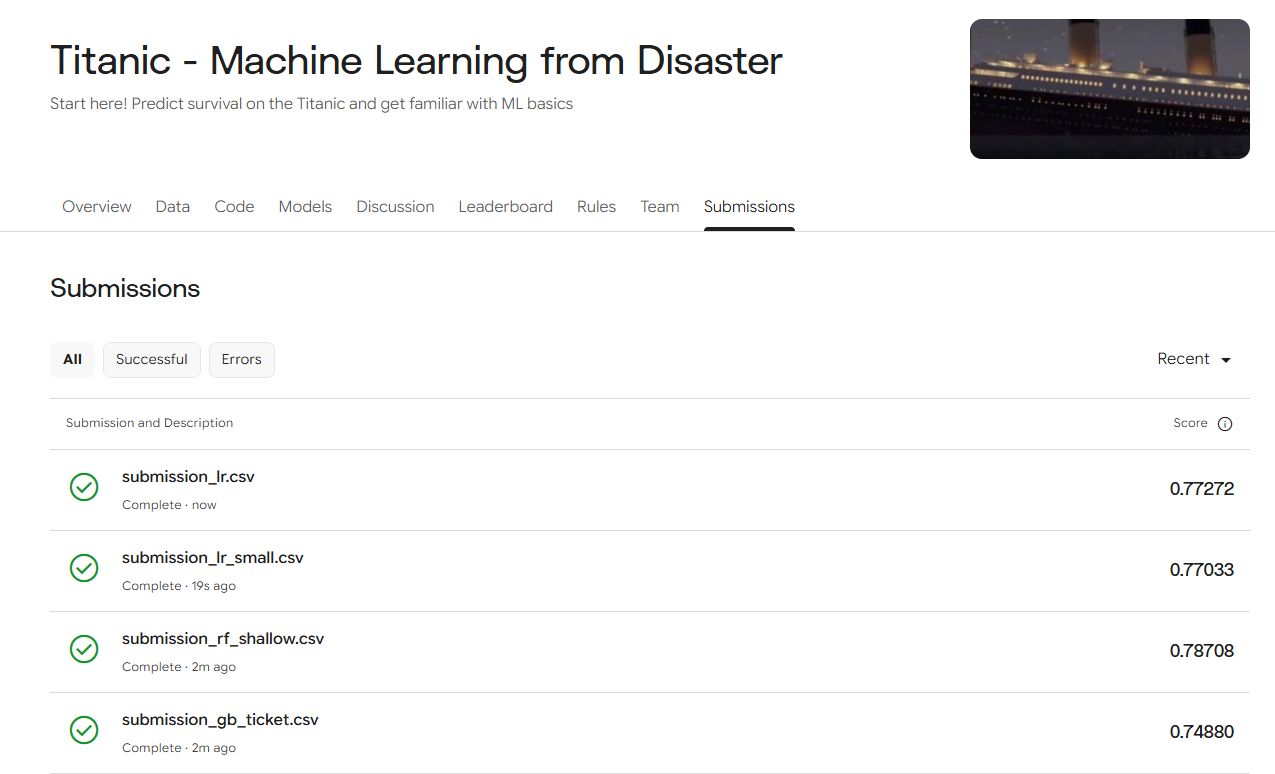

In [26]:
alt_models = {
    "rf_shallow": Pipeline([("pre", make_preprocess(scale=False, num_cols=NUM_COLS_V2)),
                            ("model", RandomForestClassifier(n_estimators=500, max_depth=5, min_samples_leaf=4,
                                                             max_features="sqrt", random_state=RANDOM_STATE))]),
    "gb_ticket": clone(model_C),
    "lr": Pipeline([("pre", make_preprocess(scale=True)),
                    ("model", LogisticRegression(C=1, max_iter=1000))]),
    "lr_small": Pipeline([("pre", make_preprocess(scale=True, num_cols=["Age", "Pclass", "FamilySize"],
                                                  cat_cols=["Sex", "Title"])),
                          ("model", LogisticRegression(C=1, max_iter=1000))]),
}

lb_rows = [{"file": "submission.csv (rf_final)",
            "repeated_cv": [r["repeated_mean"] for r in repeated_rows if r["model"] == "RandomForest +ticket (tuned)"][0],
            "diff_vs_gender": int(changed.sum())}]
alt_preds = {}
for name, m in alt_models.items():
    scores = cross_val_score(m, X, y, cv=repeated_cv, scoring="accuracy", n_jobs=-1)
    m.fit(X, y)
    pred = m.predict(X_test).astype(int)
    alt_preds[name] = pred
    pd.DataFrame({"PassengerId": test["PassengerId"], "Survived": pred}).to_csv(f"submission_{name}.csv", index=False)
    lb_rows.append({"file": f"submission_{name}.csv", "repeated_cv": scores.mean(),
                    "diff_vs_gender": int((pred != gender_sub["Survived"]).sum())})

# 캐글에 제출해 받은 Public Score (제출 후 직접 기록)
leaderboard = {"submission.csv (rf_final)": 0.76076, "submission_rf_shallow.csv": 0.78708,
               "submission_gb_ticket.csv": 0.74880, "submission_lr.csv": 0.77272,
               "submission_lr_small.csv": 0.77033}
lb_table = pd.DataFrame(lb_rows)
lb_table["leaderboard"] = lb_table["file"].map(leaderboard)
lb_table["lb_correct_of_418"] = (lb_table["leaderboard"] * 418).round().astype(int)
lb_table.sort_values("leaderboard", ascending=False).round(4)

,file,repeated_cv,diff_vs_gender,leaderboard,lb_correct_of_418
1,submission_rf_shallow.csv,0.8301,21,0.7871,329
3,submission_lr.csv,0.8290,33,0.7727,323
4,submission_lr_small.csv,0.8257,24,0.7703,322
0,submission.csv (rf_final),0.8470,58,0.7608,318
2,submission_gb_ticket.csv,0.8417,45,0.7488,313



**관찰**
1. **교차검증 순위와 리더보드 순위가 거의 반대입니다.**
   - 교차검증 1·2위였던 rf_final과 gb_ticket이 리더보드에서는 최하위 두 개입니다.
   - 둘 다 성별 규칙 견본보다도 낮습니다.
2. **성별 규칙에서 많이 벗어날수록 대체로 점수가 낮았습니다.**
   - 21명만 바꾼 rf_shallow가 1위입니다.
   - 45~58명을 바꾼 두 모델은 기준선보다 아래입니다.
   - 완전히 비례하지는 않습니다(lr은 33명을 바꿨지만 24명을 바꾼 lr_small보다 높음). 그래도 경향은 분명합니다.
3. **같은 RF라도 얕게 만들자 11명을 더 맞혔습니다**(318 → 329).
   - 교차검증 점수는 0.847 → 0.830으로 오히려 낮았습니다.
   - train 안에서만 맞던 세부 규칙을 버린 것이 새 데이터에서는 이득이었습니다.


### 10-3. 최종 제출 결정: 얕은 랜덤 포레스트 (rf_shallow)

**선택 이유**
1. **새 데이터(리더보드)에서 가장 잘 맞았습니다:** 0.78708(329/418)로, 기준선과 다른 모든 후보보다 높습니다.
2. **교차검증 점수도 충분히 높습니다:** 반복 교차검증 0.830으로 로지스틱 회귀(0.829)와 비슷합니다. 리더보드에서만 우연히 좋은 모델이 아닙니다.

최종 `submission.csv`를 이 모델의 예측으로 다시 저장합니다.

In [35]:
final_model = alt_models["rf_shallow"]
final_pred = alt_preds["rf_shallow"]

submission = pd.DataFrame({"PassengerId": test["PassengerId"], "Survived": final_pred})
submission.to_csv("submission.csv", index=False)

assert list(submission.columns) == list(gender_sub.columns)
assert len(submission) == 418 and submission["PassengerId"].equals(gender_sub["PassengerId"])
assert set(submission["Survived"].unique()) <= {0, 1}
print("최종 제출 저장 완료:", submission.shape, "/ 예측 생존 비율:", round(submission["Survived"].mean(), 3))

feature_names = final_model.named_steps["pre"].get_feature_names_out()
importances = final_model.named_steps["model"].feature_importances_
pd.Series(importances, index=feature_names).sort_values(ascending=False).head(10).round(3)

최종 제출 저장 완료: (418, 2) / 예측 생존 비율: 0.385


cat__Title_Mr           0.177
cat__Sex_female         0.162
cat__Sex_male           0.142
num__FarePerPerson      0.069
num__Pclass             0.060
num__Fare               0.058
num__TicketGroupSize    0.049
cat__Title_Miss         0.046
cat__Title_Mrs          0.044
num__FamilySize         0.039
dtype: float64

- 최종 모델의 예측 생존 비율은 train의 실제 생존율(0.384)과 거의 같습니다.
- 중요도가 성별·호칭 계열에 더 집중됩니다.
  - Title_Mr + Sex의 합: 1차 모델 0.41 → **0.48**
  - 1차 모델에서 3위였던 Age(0.106)는 상위 10위 밖으로 밀려났습니다.
  - 얕은 나무는 분할 횟수가 적어서, 가장 확실한 패턴부터 쓰고 세부 조건으로 잘게 나누지 않기 때문입니다.

## 11. 정리

- **전처리:** 결측 비율과 의미에 따라 처리 방식을 다르게 정했습니다.
  - Age: 중앙값으로 채우고 결측 표시 열 추가
  - Cabin: HasCabin·Deck 파생 변수로 대체
  - Embarked: 최빈값
  - 모든 전처리는 Pipeline 안에서 fold마다 학습해 데이터 누수를 막았습니다.
- **피처 엔지니어링:**
  - 이름에서 뽑은 **Title**이 성별에 나이 정보까지 담아 가장 효과적이었습니다.
  - 티켓 기반 변수(**TicketGroupSize, FarePerPerson**)는 랜덤 포레스트를 0.842 → 0.855로 끌어올렸습니다(반복 평가 +0.012).
- **모델 비교:**
  - 로지스틱 회귀(0.827)는 안정적이지만 비선형 패턴에 한계가 있었습니다.
  - 제한 없는 결정트리는 심하게 과적합했습니다(gap 0.20).
  - 크기를 제한한 앙상블 계열이 가장 좋았습니다.
- **앙상블 실험:**
  - 같은 특성을 쓴 모델끼리는 같은 승객을 틀려 효과가 없었습니다.
  - 특성을 나누자 예측은 다양해졌지만 약한 모델이 섞여 역시 단독 모델을 넘지 못했습니다.
  - 앙상블은 **다양성과 개별 정확도가 함께** 있어야 효과가 납니다.
- **평가에서 배운 점:**
  - 튜닝에 쓴 분할로 평가한 점수는 낙관적입니다.
  - 반복 교차검증에서 처음 1위였던 GB는 0.834로 떨어졌고, RF + 티켓은 1위를 유지했습니다.
  - 모델 선택은 **여러 분할에서도 유지되는 점수**를 근거로 해야 합니다.
- **리더보드에서 배운 점:**
  - 교차검증 1위(RF + 티켓, 0.847)의 리더보드 점수는 0.76076으로, 성별 규칙 견본보다도 낮았습니다.
  - 원인은 생존율 50%인 3등석 여성 같은 불확실한 집단을 깊은 나무가 잘게 나눠 외운 **과적합**이었습니다.
  - 교차검증 점수와 리더보드 점수의 순위가 거의 반대로 나왔습니다. **train 안의 평가만으로는 train과 test의 차이를 확인할 수 없다**는 것을 배웠습니다.
- **최종 제출:** 얕은 랜덤 포레스트(깊이 5) — 리더보드 **0.78708**(329/418).
  - 1차 제출보다 11명을 더 맞혔습니다.
  - 같은 모델에서 복잡도만 줄여 개선햇습니다.
- **Age 채우기 실험:**
  - Title·Pclass별 중앙값은 로지스틱 회귀를 0.823 → 0.830으로 올렸습니다.
  - 반대로 랜덤 포레스트는 0.847 → 0.840으로 낮췄습니다.
  - 전처리의 효과는 모델 구조에 따라 다르므로, 최종 모델(RF)에서는 전체 중앙값 + 결측 표시를 유지했습니다.
  